# Experiment 6: GloVe Word Embeddings and N-gram Language Model

**Objective:** (6.1) Generate GloVe word embeddings from a text corpus and retrieve the words most similar to **"king"**, once from scratch and once with a pretrained Gensim model. (6.2) Build a statistical N-gram language model from scratch that predicts the next word from the preceding words.

## 6.1 GloVe (Global Vectors for Word Representation)

GloVe learns vectors from **global** co-occurrence counts rather than local prediction windows alone. With $X_{ij}$ = (distance-weighted) count of word $j$ appearing in the context of word $i$, it minimises a weighted least-squares objective:

$$J=\sum_{i,j:\,X_{ij}>0} f(X_{ij})\,\big(w_i^{\top}\tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij}\big)^2, \qquad f(x)=\begin{cases}(x/x_{max})^{\alpha} & x<x_{max}\\ 1 & \text{otherwise}\end{cases}$$

The weighting $f$ dampens very frequent pairs and ignores zero counts, so dot products of word vectors encode log co-occurrence ratios. The final embedding is $w_i + \tilde{w}_i$.

### a. Without pretrained model (from scratch with NumPy)

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Read the corpus from the notebook folder or the workspace root
corpus_path = Path('glove_corpus.txt')
if not corpus_path.exists():
    corpus_path = Path('Experiment6') / 'glove_corpus.txt'
lines = corpus_path.read_text(encoding='utf-8').strip().split('\n')

# Preprocess: lowercase, keep alphabetic tokens, drop function words.
# On a 24-sentence corpus, 'the'/'a'/'is' co-occur with everything and would dominate every vector.
STOP_WORDS = {'the', 'a', 'an', 'is', 'and', 'in', 'of', 'at', 'around'}
sentences = [[w for w in re.findall(r'[a-z]+', line.lower()) if w not in STOP_WORDS] for line in lines]

vocab = sorted({w for s in sentences for w in s})
word2idx = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f'Sentences: {len(sentences)} | Tokens: {sum(map(len, sentences))} | Vocabulary size: {V}')
print('Sample:', sentences[0], sentences[4])

Sentences: 24 | Tokens: 85 | Vocabulary size: 60
Sample: ['king', 'rules', 'kingdom'] ['man', 'strong', 'brave']


In [2]:
# Build the co-occurrence matrix X (symmetric window, 1/distance weighting, no cross-sentence context)
WINDOW = 2
X = np.zeros((V, V))
for s in sentences:
    for i, w in enumerate(s):
        for j in range(max(0, i - WINDOW), min(len(s), i + WINDOW + 1)):
            if i != j:
                X[word2idx[w], word2idx[s[j]]] += 1.0 / abs(i - j)

rows, cols = np.nonzero(X)
x_ij = X[rows, cols]
print(f'Non-zero co-occurrence pairs: {len(x_ij)} of {V*V} ({len(x_ij)/(V*V):.1%} dense)')
k = word2idx['king']
print('Context counts of "king":', {vocab[j]: round(X[k, j], 2) for j in np.argsort(-X[k])[:8] if X[k, j] > 0})

Non-zero co-occurrence pairs: 188 of 3600 (5.2% dense)
Context counts of "king": {'lives': 1.0, 'powerful': 1.0, 'son': 1.0, 'queen': 1.0, 'rules': 1.0, 'rule': 0.5, 'man': 0.5, 'prince': 0.5}


In [3]:
# Train GloVe with AdaGrad (as in Pennington et al., 2014)
DIM, EPOCHS, LR, X_MAX, ALPHA = 10, 2000, 0.05, 10, 0.75
rng = np.random.default_rng(42)
W  = rng.uniform(-0.5, 0.5, (V, DIM)) / DIM     # main word vectors
Wc = rng.uniform(-0.5, 0.5, (V, DIM)) / DIM     # context word vectors
b, bc = np.zeros(V), np.zeros(V)                # biases
grad_sq = [np.ones_like(p) for p in (W, Wc, b, bc)]  # AdaGrad accumulators

f_x = np.minimum((x_ij / X_MAX) ** ALPHA, 1.0)  # weighting function f(X_ij)
log_x = np.log(x_ij)
losses = []
for epoch in range(EPOCHS):
    diff = np.sum(W[rows] * Wc[cols], axis=1) + b[rows] + bc[cols] - log_x
    losses.append(0.5 * np.sum(f_x * diff ** 2))
    g = f_x * diff
    dW, dWc, db, dbc = np.zeros_like(W), np.zeros_like(Wc), np.zeros(V), np.zeros(V)
    np.add.at(dW, rows, g[:, None] * Wc[cols])
    np.add.at(dWc, cols, g[:, None] * W[rows])
    np.add.at(db, rows, g)
    np.add.at(dbc, cols, g)
    for p, d, G in zip((W, Wc, b, bc), (dW, dWc, db, dbc), grad_sq):
        G += d ** 2
        p -= LR * d / np.sqrt(G)
    if epoch in (0, 9, 99, 499, EPOCHS - 1):
        print(f'Epoch {epoch+1:>4} | weighted loss = {losses[-1]:.6f}')

embeddings = W + Wc

Epoch    1 | weighted loss = 2.206190
Epoch   10 | weighted loss = 1.687515
Epoch  100 | weighted loss = 1.024846
Epoch  500 | weighted loss = 0.171330


Epoch 2000 | weighted loss = 0.000004


In [4]:
def most_similar(word, emb, topn=5):
    norm = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    sims = norm @ norm[word2idx[word]]
    order = [i for i in np.argsort(-sims) if vocab[i] != word][:topn]
    return [(vocab[i], float(sims[i])) for i in order]

print('--- Most similar to "king" (GloVe from scratch) ---')
for w, s in most_similar('king', embeddings):
    print(f'{w:<10} cosine = {s:.4f}')

--- Most similar to "king" (GloVe from scratch) ---
queen      cosine = 0.9700
son        cosine = 0.9035
powerful   cosine = 0.7252
wise       cosine = 0.4954
teaches    cosine = 0.4936


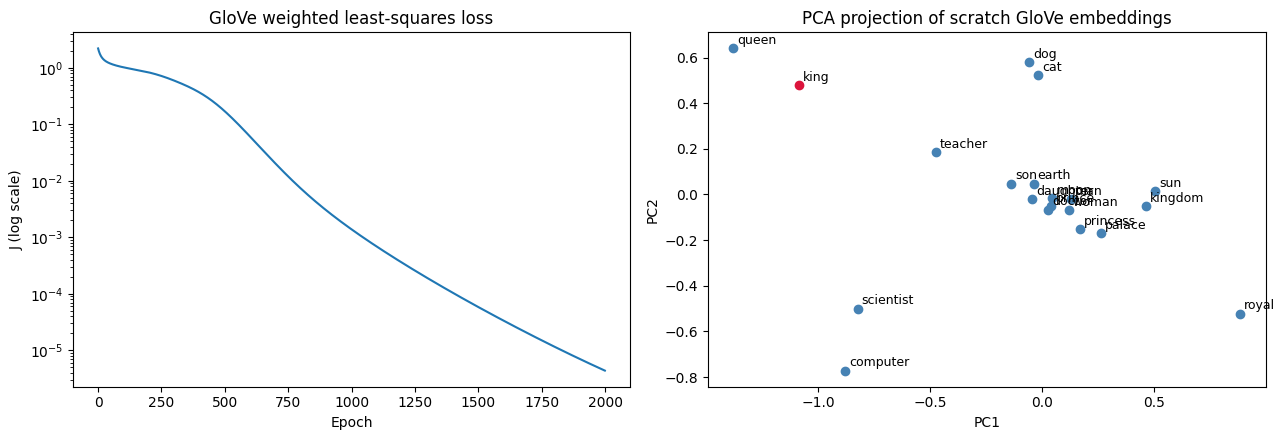

In [5]:
# Visualise: training loss and a 2-D PCA projection of the learned vectors
centered = embeddings - embeddings.mean(axis=0)
_, _, Vt = np.linalg.svd(centered, full_matrices=False)
proj = centered @ Vt[:2].T

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(losses); ax[0].set_yscale('log')
ax[0].set(title='GloVe weighted least-squares loss', xlabel='Epoch', ylabel='J (log scale)')
highlight = {'king', 'queen', 'prince', 'princess', 'man', 'woman', 'son', 'daughter', 'royal', 'palace', 'kingdom',
             'cat', 'dog', 'sun', 'moon', 'earth', 'computer', 'scientist', 'teacher', 'doctor'}
for w in highlight:
    i = word2idx[w]
    ax[1].scatter(*proj[i], c='crimson' if w == 'king' else 'steelblue')
    ax[1].annotate(w, proj[i], fontsize=9, xytext=(3, 3), textcoords='offset points')
ax[1].set(title='PCA projection of scratch GloVe embeddings', xlabel='PC1', ylabel='PC2')
plt.tight_layout(); plt.show()

**Interpretation:** The scratch model ranks **queen** first (cosine ≈ 0.97) because both words occur in identical contexts (*rules … kingdom*, *lives … royal palace*). This is GloVe's core idea: similar co-occurrence rows give similar vectors. *son* and *powerful* follow because they co-occur directly with *king*. Below rank 3, similarities fall to ≈ 0.5 (*wise*, *teaches*), which is noise from a 60-word, 85-token corpus: the loss is driven to ≈ 0, so the model memorises the 188 co-occurrence pairs instead of generalising.

### b. Using pretrained model (Gensim)

In [6]:
import gensim.downloader as api

# 100-d GloVe vectors trained on Wikipedia 2014 + Gigaword 5 (6B tokens, 400K vocabulary)
glove = api.load('glove-wiki-gigaword-100')
print(f'Pretrained vocabulary: {len(glove.key_to_index):,} words | dimension: {glove.vector_size}')

print('\n--- Most similar to "king" (pretrained GloVe, full vocabulary) ---')
for w, s in glove.most_similar('king', topn=10):
    print(f'{w:<12} cosine = {s:.4f}')

Pretrained vocabulary: 400,000 words | dimension: 100

--- Most similar to "king" (pretrained GloVe, full vocabulary) ---
prince       cosine = 0.7682
queen        cosine = 0.7508
son          cosine = 0.7021
brother      cosine = 0.6986
monarch      cosine = 0.6978
throne       cosine = 0.6920
kingdom      cosine = 0.6811
father       cosine = 0.6802
emperor      cosine = 0.6713
ii           cosine = 0.6676


In [7]:
# Fair comparison: rank only words from our corpus vocabulary using the pretrained vectors
candidates = [w for w in vocab if w != 'king' and w in glove.key_to_index]
ranked = sorted(((w, float(glove.similarity('king', w))) for w in candidates), key=lambda t: -t[1])[:5]
scratch = most_similar('king', embeddings)

print(f'{"Rank":<5} | {"Scratch GloVe":<22} | {"Pretrained GloVe (corpus vocab)"}')
print('-' * 62)
for r, ((w1, s1), (w2, s2)) in enumerate(zip(scratch, ranked), 1):
    print(f'{r:<5} | {w1:<10} {s1:>8.4f}   | {w2:<10} {s2:>8.4f}')

# Linear substructure: king - man + woman ≈ ?
print('\nAnalogy king - man + woman =', glove.most_similar(positive=['king', 'woman'], negative=['man'], topn=3))

Rank  | Scratch GloVe          | Pretrained GloVe (corpus vocab)
--------------------------------------------------------------
1     | queen        0.9700   | prince       0.7682
2     | son          0.9035   | queen        0.7508
3     | powerful     0.7252   | son          0.7021
4     | wise         0.4954   | kingdom      0.6811
5     | teaches      0.4936   | royal        0.6034

Analogy king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]


**Interpretation:** The pretrained vectors, learned from about 6 billion tokens, return a clean royalty/kinship cluster: *prince, queen, son, brother, monarch, throne, kingdom*. Restricted to the corpus vocabulary, they rank *prince, queen, son, kingdom, royal*, all semantically related, while the scratch model's tail is noisy. Pretrained similarities are lower (≈ 0.6–0.77) but more meaningful, because each word is placed relative to 400K others. Only the pretrained space supports the analogy *king − man + woman ≈ queen* (0.77); that kind of linear structure only appears with large corpora.

## 6.2 N-gram Statistical Language Model (from scratch)

An N-gram model applies the **Markov assumption**: the next word depends only on the previous $N-1$ words. Probabilities are Maximum Likelihood Estimates from counts, with add-$k$ (Laplace) smoothing to avoid zero probabilities:

$$P(w_n \mid w_{n-N+1}^{n-1}) = \frac{C(w_{n-N+1}^{n-1}\,w_n) + k}{C(w_{n-N+1}^{n-1}) + k|V|}, \qquad \text{PP}(W) = \exp\Big(-\tfrac{1}{T}\sum_{t}\log P(w_t\mid\text{context})\Big)$$

Prediction returns the highest-probability continuation. If a context was never seen, the model **backs off** to a shorter one.

In [8]:
import math
from collections import defaultdict

corpus = ('natural language processing is a branch of artificial intelligence.natural language processing enables '
          'computers to understand human language.machine learning is a branch of artificial intelligence.deep learning '
          'is a part of machine learning.language models learn patterns from text data.a language model predicts the next '
          'word in a sentence.natural language processing uses language models.artificial intelligence includes machine '
          'learning and deep learning.')

# Sentence segmentation on '.', whitespace tokenisation
sentences_lm = [s.strip().split() for s in corpus.split('.') if s.strip()]
for i, s in enumerate(sentences_lm, 1):
    print(i, ' '.join(s))

1 natural language processing is a branch of artificial intelligence
2 natural language processing enables computers to understand human language
3 machine learning is a branch of artificial intelligence
4 deep learning is a part of machine learning
5 language models learn patterns from text data
6 a language model predicts the next word in a sentence
7 natural language processing uses language models
8 artificial intelligence includes machine learning and deep learning


In [9]:
class NGramLanguageModel:
    def __init__(self, n, k=0.0):
        self.n, self.k = n, k
        self.ngram_counts = defaultdict(int)      # counts for every order 1..n
        self.context_counts = defaultdict(int)
        self.next_words = defaultdict(lambda: defaultdict(int))

    def _pad(self, sent):
        return ['<s>'] * (self.n - 1) + sent + ['</s>']

    def fit(self, sentences):
        self.vocab = {w for s in sentences for w in s} | {'</s>'}
        for sent in sentences:
            tokens = self._pad(sent)
            for order in range(1, self.n + 1):               # store all lower orders for back-off
                for i in range(self.n - 1, len(tokens)):
                    context = tuple(tokens[i - order + 1:i])
                    self.ngram_counts[context + (tokens[i],)] += 1
                    self.context_counts[context] += 1
                    self.next_words[context][tokens[i]] += 1
        return self

    def prob(self, word, context):
        context = tuple(context[-(self.n - 1):]) if self.n > 1 else ()
        num = self.ngram_counts[context + (word,)] + self.k
        den = self.context_counts[context] + self.k * len(self.vocab)
        return num / den if den else 0.0

    def predict_next(self, text, top_k=3):
        tokens = ['<s>'] * (self.n - 1) + text.lower().split()
        for order in range(self.n - 1, -1, -1):              # back off to shorter contexts if unseen
            context = tuple(tokens[len(tokens) - order:]) if order else ()
            if self.context_counts[context]:
                total = self.context_counts[context]
                cands = sorted(self.next_words[context].items(), key=lambda kv: -kv[1])[:top_k]
                return [(w, c / total) for w, c in cands], order + 1
        return [], 0

    def generate(self, seed, max_len=12):
        words = seed.lower().split()
        while len(words) < max_len:
            (nxt, _), *_ = self.predict_next(' '.join(words), top_k=1)[0]
            if nxt == '</s>':
                break
            words.append(nxt)
        return ' '.join(words)

    def perplexity(self, sentences):
        log_p, T = 0.0, 0
        for sent in sentences:
            tokens = self._pad(sent)
            for i in range(self.n - 1, len(tokens)):
                log_p += math.log(self.prob(tokens[i], tokens[i - self.n + 1:i]))
                T += 1
        return math.exp(-log_p / T)

models = {n: NGramLanguageModel(n).fit(sentences_lm) for n in (2, 3, 4)}
print(f'Vocabulary size: {len(models[2].vocab)}')
print({f'{n}-gram': sum(1 for g in m.ngram_counts if len(g) == n) for n, m in models.items()}, '(distinct n-grams of the top order)')

Vocabulary size: 35
{'2-gram': 53, '3-gram': 61, '4-gram': 63} (distinct n-grams of the top order)


In [10]:
# Next-word prediction for different contexts
queries = ['natural language', 'artificial', 'machine learning is a', 'deep learning is a part of',
           'language models learn', 'a language model predicts the next', 'computers']
for q in queries:
    print(f'\nContext: "{q}"')
    for n, m in models.items():
        preds, used = m.predict_next(q)
        pretty = ', '.join(f'{w} ({p:.2f})' for w, p in preds)
        print(f'  {n}-gram (used {used}-gram) -> {pretty}')


Context: "natural language"
  2-gram (used 2-gram) -> processing (0.43), models (0.29), </s> (0.14)
  3-gram (used 3-gram) -> processing (1.00)
  4-gram (used 4-gram) -> processing (1.00)

Context: "artificial"
  2-gram (used 2-gram) -> intelligence (1.00)
  3-gram (used 3-gram) -> intelligence (1.00)
  4-gram (used 4-gram) -> intelligence (1.00)

Context: "machine learning is a"
  2-gram (used 2-gram) -> branch (0.40), part (0.20), language (0.20)
  3-gram (used 3-gram) -> branch (0.67), part (0.33)
  4-gram (used 4-gram) -> branch (0.50), part (0.50)

Context: "deep learning is a part of"
  2-gram (used 2-gram) -> artificial (0.67), machine (0.33)
  3-gram (used 3-gram) -> machine (1.00)
  4-gram (used 4-gram) -> machine (1.00)

Context: "language models learn"
  2-gram (used 2-gram) -> patterns (1.00)
  3-gram (used 3-gram) -> patterns (1.00)
  4-gram (used 4-gram) -> patterns (1.00)

Context: "a language model predicts the next"
  2-gram (used 2-gram) -> word (1.00)
  3-gram (used

In [11]:
# Greedy generation and perplexity comparison
for seed in ['natural', 'deep learning', 'language models']:
    print(f'Seed "{seed}":')
    for n in (2, 3):
        print(f'   {n}-gram -> {models[n].generate(seed)}')

test_sentences = [s.split() for s in ['machine learning is a part of artificial intelligence',
                                      'deep learning models learn patterns from data']]
print(f'\n{"Model":<16} | {"Train PP (MLE)":<15} | {"Held-out PP (add-1)"}')
print('-' * 55)
for n in (2, 3, 4):
    train_pp = NGramLanguageModel(n).fit(sentences_lm).perplexity(sentences_lm)
    test_pp = NGramLanguageModel(n, k=1.0).fit(sentences_lm).perplexity(test_sentences)
    print(f'{n}-gram{"":<10} | {train_pp:<15.3f} | {test_pp:.3f}')

Seed "natural":
   2-gram -> natural language processing is a branch of artificial intelligence
   3-gram -> natural language processing is a branch of artificial intelligence
Seed "deep learning":
   2-gram -> deep learning is a branch of artificial intelligence
   3-gram -> deep learning is a branch of artificial intelligence
Seed "language models":
   2-gram -> language models learn patterns from text data
   3-gram -> language models learn patterns from text data

Model            | Train PP (MLE)  | Held-out PP (add-1)
-------------------------------------------------------
2-gram           | 1.795           | 16.657
3-gram           | 1.438           | 21.214
4-gram           | 1.280           | 23.794


**Interpretation:**
* **Longer context gives sharper predictions.** After *"natural language"* the bigram only sees *"language"* and spreads its probability (*processing* 0.43, *models* 0.29). The trigram conditions on *"natural language"* and is certain (*processing* 1.00). After *"deep learning is a part of"* the bigram wrongly prefers *artificial* (0.67), and the 3/4-gram models correctly predict *machine*.
* **Back-off:** for *"computers"* at the start of a sentence, the trigram context `<s> computers` never occurs, so the model falls back to the bigram (*used 2-gram*) instead of failing.
* **Sparsity trade-off:** training perplexity falls as $N$ grows (1.80 → 1.28) because the model memorises the corpus. Held-out perplexity *rises* (16.7 → 23.8) because longer n-grams are rarely seen again and smoothing spreads probability mass to unseen events. With an 8-sentence corpus, the bigram generalises best.